# Grafici delle co-occorrenze

Il notebook è diviso in tre parti più un controllo finale:

- **Parte 0 – Preparazione:** librerie e numeri presi dal notebook `co_occorrenze.ipynb`
- **Parte 1 – I numeri così come sono:** quali coppie paese + parola compaiono di più
- **Parte 2 – Confronto giusto tra paesi:** tolgo l'effetto "di quel paese si parla di più"
- **Parte 3 – Il metodo regge?** confronto tra stessa frase e finestra di 5 parole

---
# Parte 0 – Preparazione

 Librerie:
`pandas` per mettere i numeri in tabella, `matplotlib` e `seaborn` per disegnare.

In [1]:
import pandas as pd               # pandas: per mettere i numeri in tabelle (DataFrame)
import matplotlib.pyplot as plt   # pyplot: la parte di matplotlib che disegna i grafici, la chiamo plt
import seaborn as sns             # seaborn: grafici più belli con meno codice, lo chiamo sns

sns.set_theme(style="whitegrid")  # tema di seaborn: sfondo bianco con la griglia, vale per tutti i grafici sotto

## I risultati delle co-occorrenze

Ricopio qui i numeri usciti dal codice delle co-occorrenze nella stessa frase. Ogni numero = in quanti articoli c'è almeno una frase con quella nazionalità e quella parola.

Li metto direttamente in un DataFrame: le righe sono i paesi, le colonne sono le parole. Così è già pronto per i grafici.

In [2]:
paesi = ["siria", "afghanistan", "iraq", "libia", "sudan"]   # i nomi delle righe delle tabelle

# co-occorrenze con le parole NEGATIVE (stessa frase)
# ogni chiave del dizionario diventa una colonna, ogni lista contiene i 5 numeri nell'ordine dei paesi
tab_neg = pd.DataFrame({
    "arresto":      [96, 13, 50, 36, 21],
    "crimine":      [335, 80, 174, 277, 91],
    "violenza":     [139, 32, 85, 98, 62],
    "polizia":      [107, 40, 61, 57, 16],
    "sicurezza":    [577, 106, 405, 407, 112],
    "profugo":      [336, 34, 92, 62, 45],
    "immigrazione": [55, 14, 14, 120, 13],
}, index=paesi)   # index=paesi mette i nomi dei paesi come etichette delle righe

# co-occorrenze con le parole POSITIVE (stessa frase)
tab_pos = pd.DataFrame({
    "regolare":     [23, 2, 25, 12, 6],
    "assolto":      [1, 0, 0, 0, 0],
    "liberta":      [132, 14, 40, 53, 14],
    "accoglienza":  [95, 11, 24, 59, 18],
    "pace":         [146, 28, 43, 69, 35],
    "integrazione": [12, 4, 4, 8, 4],
    "sicuro":       [52, 19, 23, 72, 8],
}, index=paesi)

# totali con la finestra di 5 parole (ultima cella del primo notebook)
tab_finestra = pd.DataFrame({
    "negative": [709, 113, 406, 405, 112],
    "positive": [216, 31, 61, 95, 22],
}, index=paesi)

print(tab_neg)   # stampo le tabelle per controllare che i numeri siano giusti
print()          # riga vuota, solo per separare
print(tab_pos)

             arresto  crimine  violenza  polizia  sicurezza  profugo  \
siria             96      335       139      107        577      336   
afghanistan       13       80        32       40        106       34   
iraq              50      174        85       61        405       92   
libia             36      277        98       57        407       62   
sudan             21       91        62       16        112       45   

             immigrazione  
siria                  55  
afghanistan            14  
iraq                   14  
libia                 120  
sudan                  13  

             regolare  assolto  liberta  accoglienza  pace  integrazione  \
siria              23        1      132           95   146            12   
afghanistan         2        0       14           11    28             4   
iraq               25        0       40           24    43             4   
libia              12        0       53           59    69             8   
sudan             

## Quante volte compare ogni paese

Questi numeri servono nella Parte 2. Li prendo dalla prima cella del primo notebook (quella con il `Counter`) e sommo tutte le varianti di ogni paese (es. siria + siriano + siriana + siriani + siriane).

In [3]:
# occorrenze di ogni paese prese dal Counter del primo notebook (somma di tutte le varianti)
# pd.Series è come una colonna sola: a ogni paese associo un numero
menzioni = pd.Series({
    "siria":       6498 + 1745 + 933 + 1798 + 392,   # siria, siriano, siriana, siriani, siriane
    "afghanistan": 1603 + 130 + 94 + 162 + 65,       # afghanistan, afghano, afghana, afghani, afghane
    "iraq":        3707 + 890 + 393 + 487 + 402,     # iraq, iracheno, irachena, iracheni, irachene
    "libia":       4322 + 761 + 830 + 571 + 598,     # libia, libico, libica, libici, libiche
    "sudan":       1598 + 173 + 202,                 # sudan, sudanese, sudanesi
})
print("Quante volte compare ogni paese:")
print(menzioni)

Quante volte compare ogni paese:
siria          11366
afghanistan     2054
iraq            5879
libia           7082
sudan           1973
dtype: int64


---
# Parte 1 – I numeri così come sono

Qui guardo i numeri assoluti: quante volte ogni paese compare vicino a ogni parola. Attenzione che la Siria avrà quasi sempre i numeri più alti, perché è il paese di cui si parla di più (lo sistemo nella Parte 2).

## Grafico 1 – Heatmap delle parole negative

Una heatmap è una tabella colorata: più il quadratino è scuro, più il numero è alto. `annot=True` scrive il numero dentro ogni quadratino.

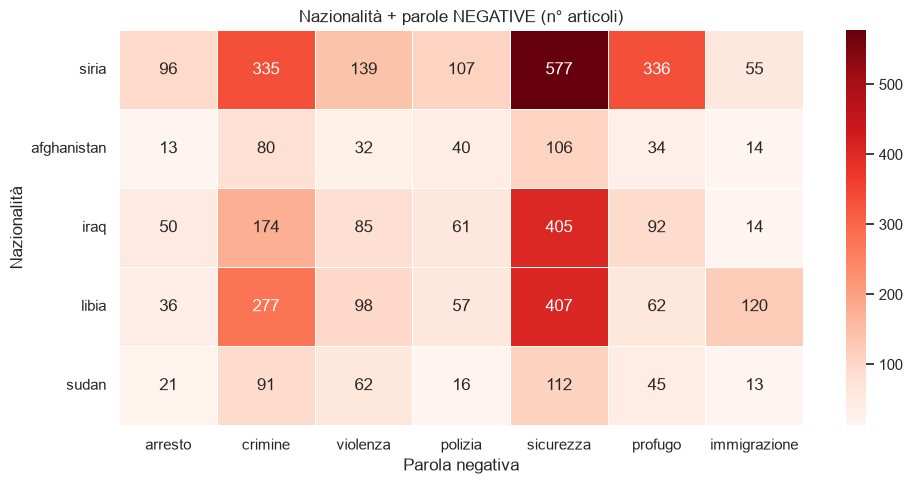

In [4]:
plt.figure(figsize=(10, 5))        # crea un foglio nuovo per il grafico: 10 di larghezza, 5 di altezza (in pollici)
sns.heatmap(tab_neg,               # la tabella da colorare
            annot=True,            # scrive il numero dentro ogni quadratino
            fmt="d",               # formato del numero: "d" = numero intero, senza virgola
            cmap="Reds",           # scala di colori: dal rosso chiaro (pochi) al rosso scuro (tanti)
            linewidths=0.5)        # spessore delle righe bianche tra un quadratino e l'altro
plt.title("Nazionalità + parole NEGATIVE (n° articoli)")   # titolo in alto
plt.xlabel("Parola negativa")      # scritta sotto l'asse orizzontale (x)
plt.ylabel("Nazionalità")          # scritta di fianco all'asse verticale (y)
plt.yticks(rotation=0)             # i nomi dei paesi dritti (se no seaborn li gira in verticale)
plt.tight_layout()                 # sistema i margini così non viene tagliato niente
plt.show()                         # mostra il grafico

La colonna più scura è **sicurezza** per tutti i paesi (Siria 577, Libia 407, Iraq 405). Subito dopo c'è **crimine**. La Siria è la riga più scura in generale, ma è anche il paese di cui si parla di più. "Immigrazione" è bassa ovunque tranne che per la Libia (120), probabilmente per le partenze dei barconi verso l'Italia.

## Grafico 2 – Heatmap delle parole positive
Stessa cosa, in verde, per le parole positive.

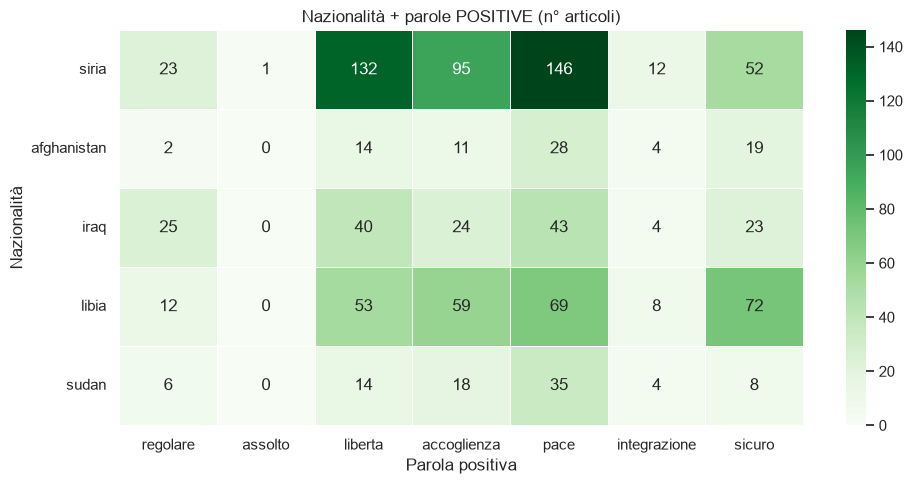

In [5]:
plt.figure(figsize=(10, 5))        # foglio nuovo 10x5
sns.heatmap(tab_pos,               # stavolta la tabella delle positive
            annot=True,            # numero dentro ogni quadratino
            fmt="d",               # numero intero
            cmap="Greens",         # scala di verdi: più scuro = più articoli
            linewidths=0.5)        # righe bianche di separazione
plt.title("Nazionalità + parole POSITIVE (n° articoli)")   # titolo
plt.xlabel("Parola positiva")      # etichetta asse x
plt.ylabel("Nazionalità")          # etichetta asse y
plt.yticks(rotation=0)             # nomi dei paesi dritti
plt.tight_layout()                 # sistema i margini
plt.show()                         # mostra il grafico

 I numeri sono molto più bassi: il massimo qui è 146 (siria + pace), nelle negative era 577. Le parole positive più presenti sono **pace** e **libertà**, ma probabilmente si riferiscono alla guerra e alle trattative, non alle persone. "Assolto" è praticamente zero e "integrazione" quasi: di queste nazionalità non si parla quasi mai in termini di integrazione.

## Grafico 3 – Quali parole pesano di più (tutti i paesi insieme)

Nuovo grafico: sommo ogni colonna su tutti e 5 i paesi, così vedo quali parole fanno "il grosso" dei risultati. Serve a capire se il risultato negativo dipende da tante parole o solo da una o due.

`.sum()` senza niente dentro somma lungo le colonne (cioè somma i 5 paesi di ogni parola).

              articoli      tipo
sicurezza         1607  negativa
crimine            957  negativa
profugo            569  negativa
violenza           416  negativa
pace               321  positiva
polizia            281  negativa
liberta            253  positiva
arresto            216  negativa
immigrazione       216  negativa
accoglienza        207  positiva
sicuro             174  positiva
regolare            68  positiva
integrazione        32  positiva
assolto              1  positiva


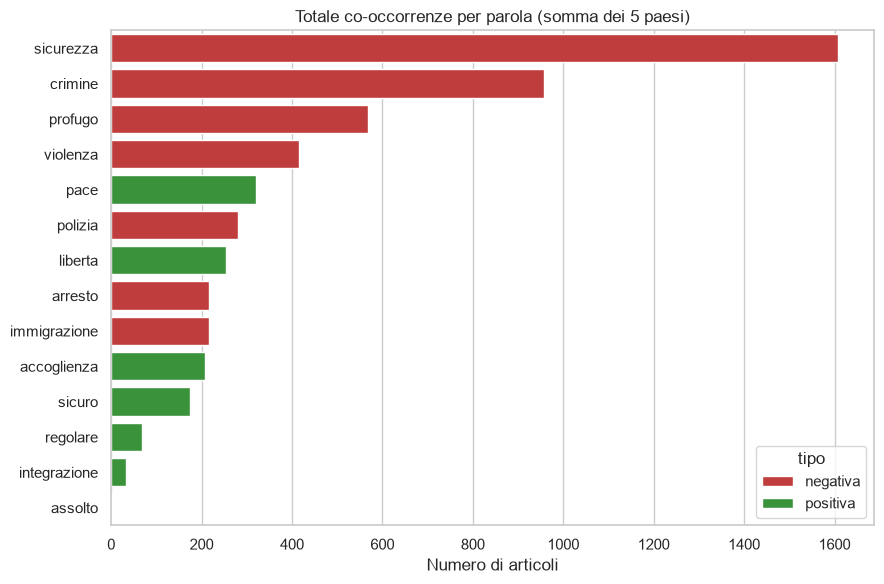

In [6]:
# totale di ogni parola su tutti i paesi
per_parola = pd.concat([
    pd.DataFrame({"articoli": tab_neg.sum(), "tipo": "negativa"}),   # tab_neg.sum() = una somma per ogni colonna
    pd.DataFrame({"articoli": tab_pos.sum(), "tipo": "positiva"}),
])
per_parola = per_parola.sort_values("articoli", ascending=False)    # dalla parola più frequente alla meno
print(per_parola)

plt.figure(figsize=(9, 6))           # foglio nuovo 9x6
sns.barplot(x=per_parola["articoli"],     # lunghezza della barra = totale articoli
            y=per_parola.index,           # una barra per ogni parola (barre orizzontali)
            hue=per_parola["tipo"],       # colore in base al tipo di parola
            palette={"negativa": "#d62728", "positiva": "#2ca02c"},   # rosso = negativa, verde = positiva
            dodge=False)                  # una barra sola per parola
plt.title("Totale co-occorrenze per parola (somma dei 5 paesi)")
plt.xlabel("Numero di articoli")     # etichetta asse x
plt.ylabel("")                       # le parole si spiegano da sole
plt.tight_layout()                   # sistema i margini
plt.show()                           # mostra il grafico

"Sicurezza" da sola fa 1607 articoli, più di tutte le parole positive messe insieme (1056). Al secondo posto c'è "crimine" (957). La prima parola positiva è "pace" (321), che sta solo al quinto posto, dopo anche "profugo" e "violenza". Quindi il risultato negativo non dipende da una sola parola: anche togliendo "sicurezza", le negative restano molte di più.

## Grafico 4 – Le 15 coppie più frequenti

Metto tutte le coppie paese + parola in un'unica lista e prendo le 15 più frequenti, colorate in base al tipo di parola. È il "riepilogo ordinato" del primo notebook, ma disegnato.

`.stack()` trasforma la tabella in una lista lunga di righe (paese, parola, numero).

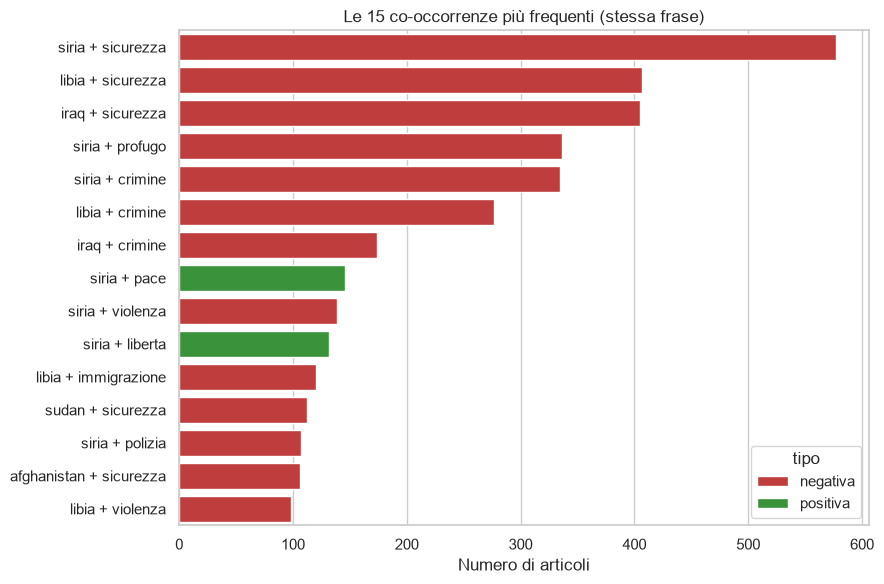

tipo
negativa    13
positiva     2
Name: count, dtype: int64


In [7]:
# .stack() trasforma la tabella in una lista lunga: una riga per ogni coppia (paese, parola)
# .reset_index() trasforma paese e parola in colonne normali
lista_neg = tab_neg.stack().reset_index()
lista_neg.columns = ["paese", "parola", "articoli"]   # do un nome alle 3 colonne
lista_neg["tipo"] = "negativa"                        # colonna che dice che tipo di parola è (servirà per il colore)

lista_pos = tab_pos.stack().reset_index()             # stessa cosa per le positive
lista_pos.columns = ["paese", "parola", "articoli"]
lista_pos["tipo"] = "positiva"

tutte = pd.concat([lista_neg, lista_pos])                      # metto le due liste una sotto l'altra
tutte["coppia"] = tutte["paese"] + " + " + tutte["parola"]     # creo l'etichetta tipo "siria + sicurezza"
top15 = tutte.sort_values("articoli", ascending=False).head(15)   # ordino dal più grande e tengo i primi 15

plt.figure(figsize=(9, 6))         # foglio nuovo 9x6
sns.barplot(data=top15,            # la tabella da cui prendere i dati
            x="articoli",          # lunghezza delle barre = numero di articoli
            y="coppia",            # una barra per ogni coppia -> barre orizzontali (più leggibili con nomi lunghi)
            hue="tipo",            # colora le barre in base alla colonna "tipo"
            palette={"negativa": "#d62728", "positiva": "#2ca02c"},   # quale colore per ogni tipo
            dodge=False)           # una barra sola per coppia, non divisa in due per tipo
plt.title("Le 15 co-occorrenze più frequenti (stessa frase)")
plt.xlabel("Numero di articoli")   # etichetta asse x
plt.ylabel("")                     # niente etichetta sull'asse y, le coppie si spiegano da sole
plt.tight_layout()                 # sistema i margini
plt.show()                         # mostra il grafico

print(top15["tipo"].value_counts())   # conta quante coppie negative e quante positive ci sono nella top 15

Su 15 coppie, 13 sono negative e solo 2 positive (siria + pace e siria + libertà). Al primo posto c'è siria + sicurezza, e "sicurezza" occupa anche il secondo e il terzo posto con Libia e Iraq.

---
# Parte 2 – Confronto giusto tra paesi

Nella Parte 1 la Siria vince quasi sempre, ma solo perché se ne parla molto di più (11.366 menzioni contro le 1.973 del Sudan). Qui uso due trucchi per confrontare i paesi alla pari:
- dividere per quante volte compare il paese (Grafico 5)
- usare le percentuali invece dei numeri (Grafici 6 e 7)

## Grafico 5 – Heatmap in rapporto a quanto si parla del paese

Divido ogni riga per **quante volte compare quel paese** (i numeri della sezione 0.3) e moltiplico per 1000, così il numero si legge come "co-occorrenze ogni 1000 volte che il paese viene nominato".

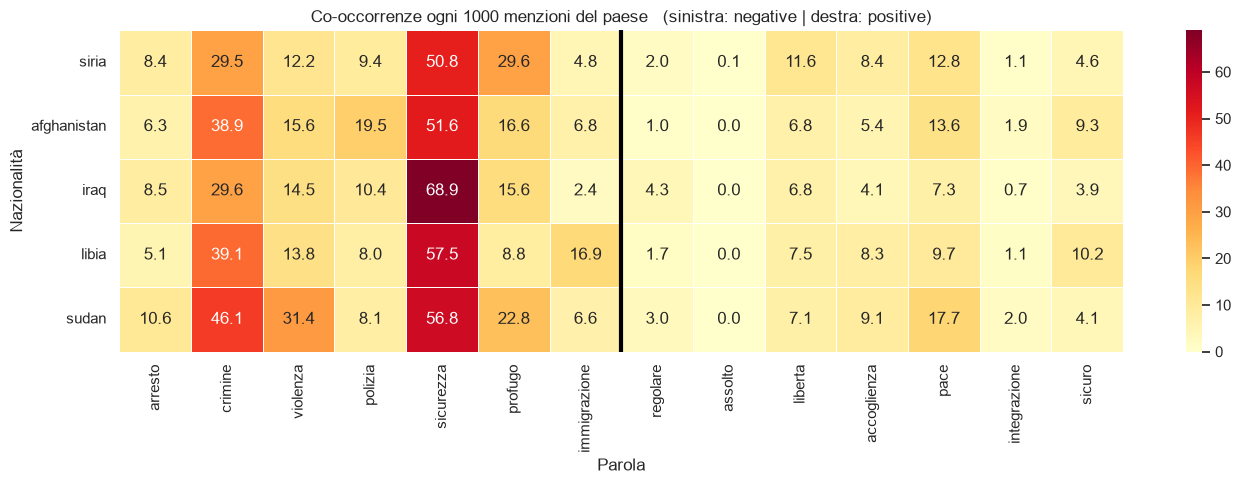

In [8]:
# metto negative e positive nella stessa tabella, una accanto all'altra
# axis=1 vuol dire "attacca le colonne di fianco" (axis=0 le metterebbe sotto)
tab_tutte = pd.concat([tab_neg, tab_pos], axis=1)

# divido ogni riga per le menzioni del suo paese (axis=0 = ogni riga per il suo numero) e moltiplico per 1000
tab_1000 = tab_tutte.div(menzioni, axis=0) * 1000

plt.figure(figsize=(14, 5))        # foglio più largo (14) perché ci sono 14 colonne
sns.heatmap(tab_1000,              # la tabella "ogni 1000 menzioni"
            annot=True,            # numero dentro i quadratini
            fmt=".1f",             # numero con 1 cifra dopo la virgola (qui non sono più interi)
            cmap="YlOrRd",         # scala giallo -> arancione -> rosso
            linewidths=0.5)        # righe bianche di separazione
plt.axvline(len(tab_neg.columns),  # disegna una linea verticale dopo la 7a colonna (le 7 negative)
            color="black",         # colore della linea
            linewidth=3)           # spessore della linea, così separa bene negative | positive
plt.title("Co-occorrenze ogni 1000 menzioni del paese   (sinistra: negative | destra: positive)")
plt.xlabel("Parola")               # etichetta asse x
plt.ylabel("Nazionalità")          # etichetta asse y
plt.yticks(rotation=0)             # nomi dei paesi dritti
plt.tight_layout()                 # sistema i margini
plt.show()                         # mostra il grafico

Qui i paesi si confrontano in modo giusto, e la classifica cambia rispetto ai numeri assoluti. La Siria non domina più: per "sicurezza" il valore più alto è l'**Iraq** (circa 69 ogni 1000 menzioni), poi la Libia (57), mentre la Siria è a circa 51. Il **Sudan**, di cui si parla poco, viene fuori molto: è il primo per "crimine" (46, la Libia è seconda con 39) e per "violenza" (31, più del doppio degli altri). La Libia invece è la prima per "immigrazione" (17). La parte destra (positive) resta in generale molto più chiara della sinistra per tutti i paesi e ciò risulta in linea con le analisi precedenti.

## Grafico 6 – Di cosa si parla per ogni paese

Nuovo grafico: per ogni paese guardo **come si dividono le sue co-occorrenze negative** tra le 7 parole. Divido ogni riga per il suo totale e moltiplico per 100, così ogni paese arriva a 100%. È una barra orizzontale impilata: ogni colore è una parola.

Così vedo il "profilo" di ogni paese: per esempio se di uno si parla più in termini di crimine e di un altro più in termini di profughi.

             arresto  crimine  violenza  polizia  sicurezza  profugo  \
siria            5.8     20.4       8.4      6.5       35.1     20.4   
afghanistan      4.1     25.1      10.0     12.5       33.2     10.7   
iraq             5.7     19.8       9.6      6.9       46.0     10.4   
libia            3.4     26.2       9.3      5.4       38.5      5.9   
sudan            5.8     25.3      17.2      4.4       31.1     12.5   

             immigrazione  
siria                 3.3  
afghanistan           4.4  
iraq                  1.6  
libia                11.4  
sudan                 3.6  


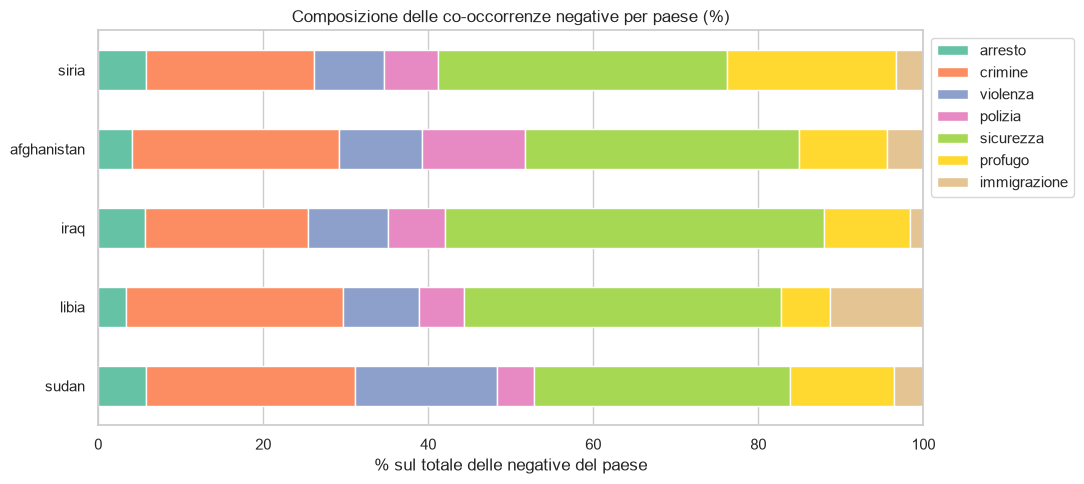

In [9]:
# ogni riga diviso il suo totale -> percentuali che per ogni paese sommano a 100
profilo_neg = tab_neg.div(tab_neg.sum(axis=1), axis=0) * 100
print(profilo_neg.round(1))

profilo_neg.plot(kind="barh",                      # barh = barre orizzontali
                 stacked=True,                     # i pezzi delle parole uno dopo l'altro nella stessa barra
                 figsize=(11, 5),                  # dimensione del grafico
                 color=sns.color_palette("Set2", 7))   # 7 colori diversi e distinguibili, uno per parola
plt.title("Composizione delle co-occorrenze negative per paese (%)")
plt.xlabel("% sul totale delle negative del paese")   # etichetta asse x
plt.ylabel("")                     # i nomi dei paesi bastano
plt.xlim(0, 100)                   # asse x da 0 a 100
plt.gca().invert_yaxis()           # gca() = "il grafico attuale"; inverto l'asse y così la siria è in alto come nelle tabelle
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))   # legenda fuori, a destra
plt.tight_layout()                 # sistema i margini
plt.show()                         # mostra il grafico

"Sicurezza" è il pezzo più grande per tutti, ma con pesi diversi: per l'Iraq è quasi metà (46%), per il Sudan circa un terzo (31%). La Siria è l'unico paese dove "profugo" pesa quanto "crimine" (20% ciascuno), e questo torna con la guerra e le fughe dal paese. La Libia ha la quota più alta di "immigrazione" (11%, gli altri stanno sotto il 5%), il Sudan quella di "violenza" (17%) e l'Afghanistan quella di "polizia" (circa 13%). Quindi i paesi non sono raccontati tutti allo stesso modo: ognuno ha il suo tema negativo prevalente.

## Grafico 7 – Quanta parte è negativa e quanta positiva

Sommo tutte le colonne di ogni tabella con `.sum(axis=1)` (somma lungo la riga), così ho un totale negativo e uno positivo per ogni paese. Poi li trasformo in **percentuali** (negative + positive = 100%) e faccio una barra impilata: la parte rossa è la quota negativa, quella verde la quota positiva. Così conta *come* si parla di un paese e non *quanto*.

             negative  positive  % negative  % positive
siria            1645       461        78.1        21.9
afghanistan       319        78        80.4        19.6
iraq              881       159        84.7        15.3
libia            1057       273        79.5        20.5
sudan             360        85        80.9        19.1


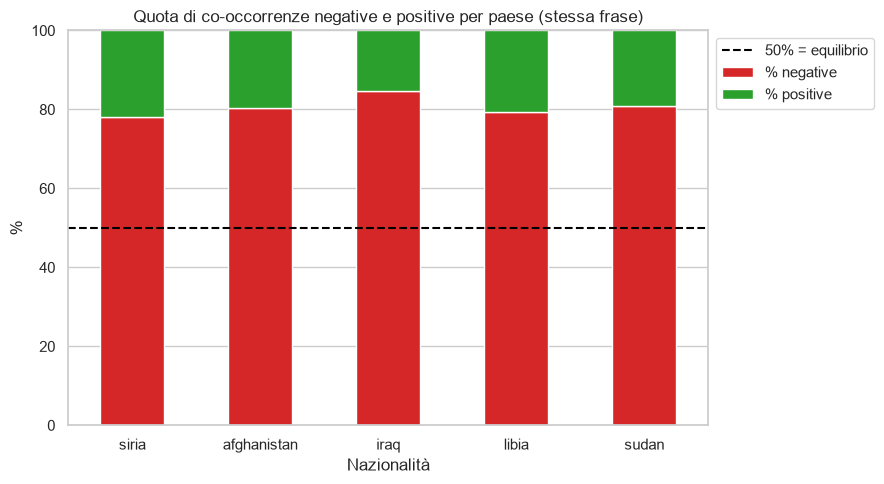

Media della % di negative tra i 5 paesi: 80.7 %


In [10]:
totali = pd.DataFrame({
    "negative": tab_neg.sum(axis=1),   # sum(axis=1) somma tutti i numeri di una riga -> totale negative per paese
    "positive": tab_pos.sum(axis=1),   # stessa cosa per le positive
})
totali["% negative"] = totali["negative"] / (totali["negative"] + totali["positive"]) * 100   # quota negativa in %
totali["% positive"] = 100 - totali["% negative"]                                             # il resto fino a 100
print(totali.round(1))   # round(1) arrotonda a 1 cifra dopo la virgola, solo per leggere meglio

# .plot() di pandas disegna direttamente le colonne della tabella
totali[["% negative", "% positive"]].plot(kind="bar",        # grafico a barre verticali
                                          stacked=True,      # barre una SOPRA l'altra invece che affiancate
                                          figsize=(9, 5),    # dimensione del grafico
                                          color=["#d62728", "#2ca02c"])   # rosso per le negative, verde per le positive
plt.axhline(50,                    # linea orizzontale all'altezza 50
            color="black",         # nera
            linestyle="--",        # tratteggiata
            label="50% = equilibrio")   # testo che compare nella legenda
plt.title("Quota di co-occorrenze negative e positive per paese (stessa frase)")
plt.xlabel("Nazionalità")          # etichetta asse x
plt.ylabel("%")                    # etichetta asse y
plt.ylim(0, 100)                   # l'asse y va da 0 a 100, così ogni barra è alta tutta
plt.xticks(rotation=0)             # nomi dei paesi orizzontali (pandas di default li gira di 90°)
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))   # legenda fuori dal grafico, a destra, così non copre le barre
plt.tight_layout()                 # sistema i margini (serve anche per far stare la legenda)
plt.show()                         # mostra il grafico

print("Media della % di negative tra i 5 paesi:", round(totali["% negative"].mean(), 1), "%")   # .mean() = media

 Per tutti i paesi la parte rossa va ben oltre la linea del 50%. In media circa l'81% delle co-occorrenze è negativa, cioè 4 su 5. L'Iraq è il più alto (circa 85%), la Siria il più basso (circa 78%): ha tante negative ma anche parecchie positive (pace, libertà).

---
# Parte 3 – Il metodo regge?

## Grafico 8 – Stessa frase vs finestra di 5 parole

Precedentemente abbiamo cercato le parole nella **stessa frase** e a **massimo 5 parole di distanza**. Qui confronto la percentuale di negative con i due metodi, per vedere se il risultato cambia.

             stessa frase  finestra 5 parole
siria                78.1               76.6
afghanistan          80.4               78.5
iraq                 84.7               86.9
libia                79.5               81.0
sudan                80.9               83.6


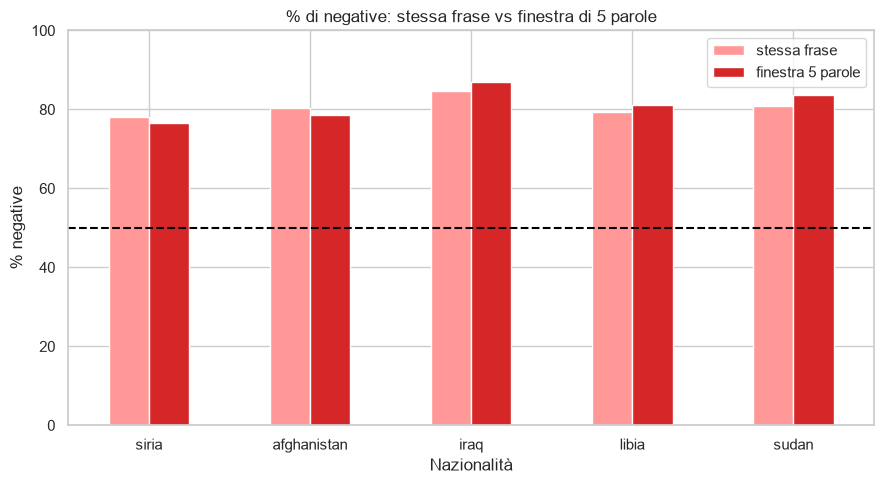

In [11]:
# stessa percentuale di prima ma con i totali della finestra di 5 parole
tab_finestra["% negative"] = tab_finestra["negative"] / (tab_finestra["negative"] + tab_finestra["positive"]) * 100

# tabella con le due percentuali una accanto all'altra: una colonna per metodo
confronto = pd.DataFrame({
    "stessa frase": totali["% negative"],
    "finestra 5 parole": tab_finestra["% negative"],
})
print(confronto.round(1))

confronto.plot(kind="bar",                       # barre verticali, stavolta NON impilate: una accanto all'altra
               figsize=(9, 5),                   # dimensione del grafico
               color=["#ff9896", "#d62728"])     # rosa = stessa frase, rosso scuro = finestra 5 parole
plt.axhline(50, color="black", linestyle="--")   # linea tratteggiata del 50% come riferimento
plt.title("% di negative: stessa frase vs finestra di 5 parole")
plt.xlabel("Nazionalità")          # etichetta asse x
plt.ylabel("% negative")           # etichetta asse y
plt.ylim(0, 100)                   # asse y da 0 a 100
plt.xticks(rotation=0)             # nomi dei paesi orizzontali
plt.tight_layout()                 # sistema i margini
plt.show()                         # mostra il grafico

Con la finestra di 5 parole i numeri assoluti sono più bassi (perché la condizione è più stretta), ma le percentuali restano quasi uguali, tutte intorno all'80%. Quindi il risultato non dipende dal metodo scelto: è abbastanza solido.